# Step 2 · 2주차 — 전처리와 특징 추출
컴퓨터소프트웨어학부 22114553 전진성 · https://github.com/jjs523/semg-gesture-angle

원신호를 윈도우당 25차원 특징 벡터로 바꾸고, 시행 단위로 먼저 나눈 데이터셋 `data/dataset.npz`를 만든다. 실행: `python main.py week2` (약 4분) 후 이 노트북.

In [1]:
import os, sys, json
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')
sys.path.insert(0, 'src')
import numpy as np, pandas as pd
from IPython.display import Image, display
import common as C, features as F
X, meta = C.load_all()
print('시행 배열', X.shape)

시행 배열 (1920, 5000, 5)


## 단계 1 · 필터 적용 — 60 Hz 노치 + 20~450 Hz 4차 Butterworth, `filtfilt(axis=0)`

전: [0.0208 0.0518 0.0377 0.0119 0.0049]
후: [0.0199 0.0501 0.0369 0.0113 0.0044]


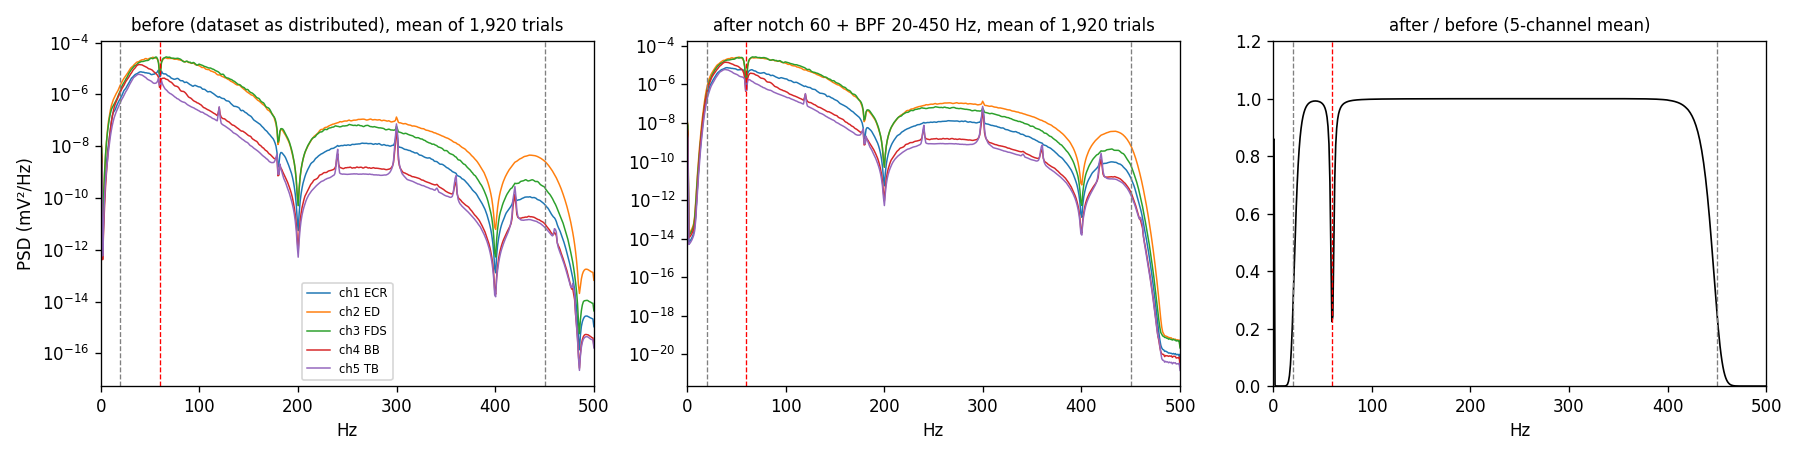

In [2]:
Xf = F.preprocess(X.astype(np.float64)).astype(np.float32)
i0 = meta.index[(meta.participant=='a')&(meta.label=='30_fist')&(meta.trial==0)][0]
print('전:', X[i0].std(0).round(4))
print('후:', Xf[i0].std(0).round(4))
display(Image('results/week2/filter_check.png'))

## 단계 2 · 분석 구간 — mark + 1.0~3.0 s (1주차에 측정한 활성 구간 0.72~3.22 s 근거, 재현 가정)

세그먼트 모양: (2000, 5)


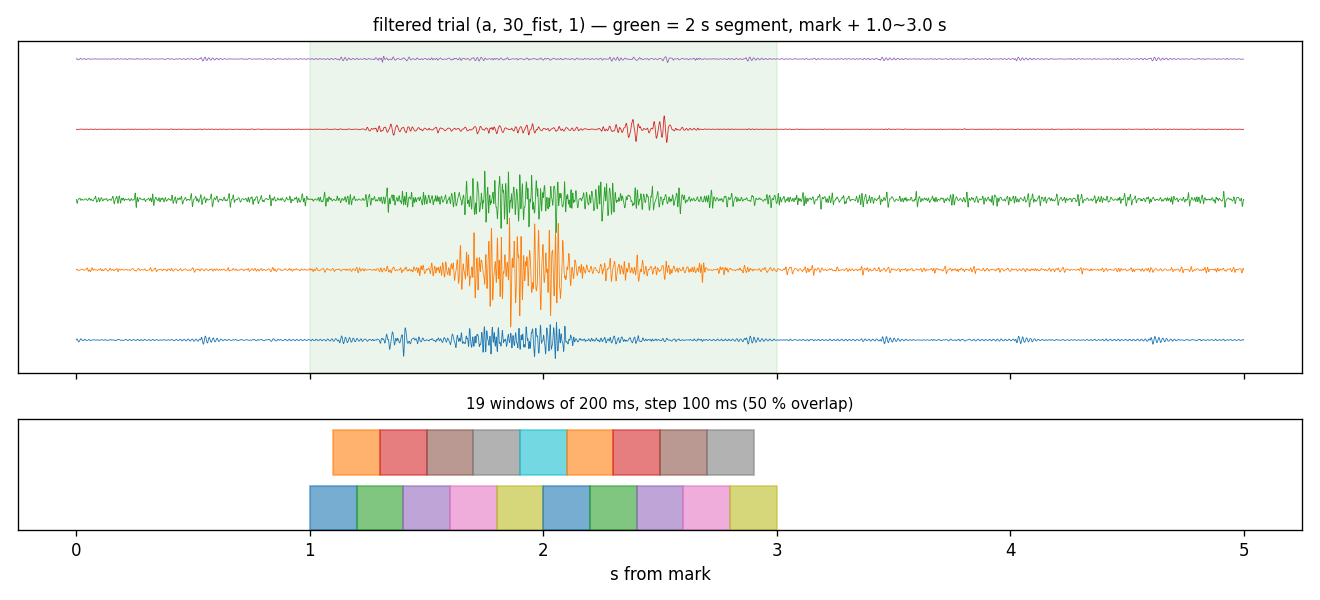

In [3]:
seg = F.cut(Xf[i0]); print('세그먼트 모양:', seg.shape)
display(Image('results/week2/segment_windows.png'))

## 단계 3 · 슬라이딩 윈도우 — 200 ms, 100 ms 간격

In [4]:
w = F.make_windows(seg); print('윈도우 배열:', w.shape, '  (2000-200)/100+1 =', (2000-200)//100+1)

윈도우 배열: (19, 200, 5)   (2000-200)/100+1 = 19


## 단계 4 · 시간영역 특징 — 논문 식 (1)~(5), ZC만 임계값 0.01

In [5]:
import inspect; print(inspect.getsource(F.td_features))
f = F.td_features(w[0]); print('특징 벡터:', f.shape)
print(dict(zip(F.FEATURE_NAMES, np.round(f, 4))))

def td_features(w, th=ZC_TH):
    """w: (..., win, C) -> (..., 5*C). 마지막 축 순서 = [RMS x C, MAV x C, WL x C, ZC x C, SSC x C]"""
    d = np.diff(w, axis=-2)
    rms = np.sqrt(np.mean(w ** 2, axis=-2))
    mav = np.mean(np.abs(w), axis=-2)
    wl = np.sum(np.abs(d), axis=-2)
    zc = np.sum((w[..., :-1, :] * w[..., 1:, :] < 0) & (np.abs(d) >= th), axis=-2)            # 식 (4): 임계값 th
    ssc = np.sum((w[..., 1:-1, :] - w[..., :-2, :]) * (w[..., 1:-1, :] - w[..., 2:, :]) > 0, axis=-2)  # 식 (5): 임계값 없음
    return np.concatenate([rms, mav, wl, zc, ssc], axis=-1).astype(np.float32)

특징 벡터: (25,)
{'RMS_ECR': np.float32(0.0112), 'RMS_ED': np.float32(0.0071), 'RMS_FDS': np.float32(0.0176), 'RMS_BB': np.float32(0.0014), 'RMS_TB': np.float32(0.0053), 'MAV_ECR': np.float32(0.0085), 'MAV_ED': np.float32(0.0057), 'MAV_FDS': np.float32(0.0124), 'MAV_BB': np.float32(0.0011), 'MAV_TB': np.float32(0.004), 'WL_ECR': np.float32(0.6664), 'WL_ED': np.float32(0.4799), 'WL_FDS': np.float32(1.3162), 'WL_BB': np.

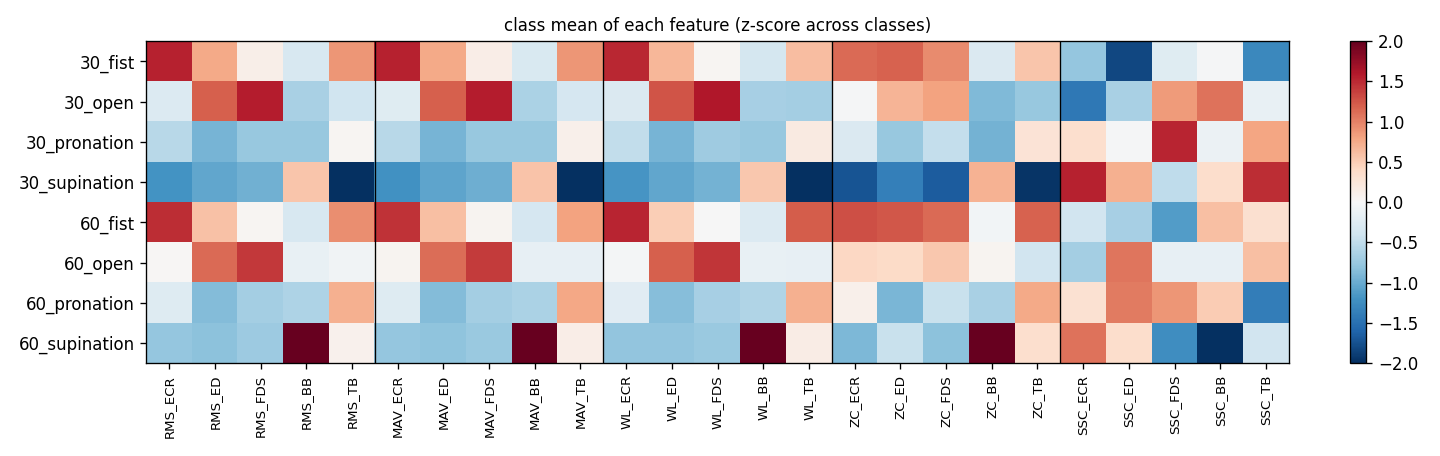

In [6]:
display(Image('results/week2/feature_class_heatmap.png'))

## 단계 5 · 데이터셋 — **시행 단위로 먼저 나눈 뒤** 각 집합 안에서만 윈도우·특징 생성

In [7]:
from sklearn.model_selection import train_test_split
strat = (meta.label + '_' + meta.participant).values          # 클래스 x 피험자 층화
tr_idx, te_idx = train_test_split(np.arange(len(meta)), test_size=0.2, stratify=strat, random_state=42)  # 1) 시행 단위 분할
assert not set(tr_idx) & set(te_idx)
Xtr = F.trial_features(Xf[np.sort(tr_idx)]).reshape(-1, 25)   # 2) 학습 시행 안에서만 특징
Xte = F.trial_features(Xf[np.sort(te_idx)]).reshape(-1, 25)   #    테스트 시행 안에서만 특징
print(Xtr.shape, Xte.shape, '비율', len(Xtr)/len(Xte))
pd.read_csv('results/week2/dataset_summary.csv', index_col=0)

(29184, 25) (7296, 25) 비율 4.0


,학습 시행,테스트 시행,학습 윈도우,테스트 윈도우
30_fist,192,48,3648,912
30_open,192,48,3648,912
30_pronation,192,48,3648,912
30_supination,192,48,3648,912
60_fist,192,48,3648,912
60_open,192,48,3648,912
60_pronation,192,48,3648,912
60_supination,192,48,3648,912
합계,1536,384,29184,7296


## 단계 6 · 표준화와 저장 — StandardScaler 를 학습셋에만 fit

In [8]:
d = np.load('data/dataset.npz', allow_pickle=True)
print({k: d[k].shape for k in d.files})
print('학습 평균 |최대|', abs(d['Xtr'].mean(0)).max().round(6), ' 학습 표준편차', d['Xtr'].std(0).min().round(4), '~', d['Xtr'].std(0).max().round(4))
print('테스트 평균 |최대|', abs(d['Xte'].mean(0)).max().round(3), ' 테스트 표준편차', d['Xte'].std(0).min().round(3), '~', d['Xte'].std(0).max().round(3))

{'Xtr': (29184, 25), 'ytr': (29184,), 'Xte': (7296, 25), 'yte': (7296,), 'trial_tr': (29184,), 'trial_te': (7296,), 'pos_tr': (29184,), 'pos_te': (7296,), 'feature_names': (25,), 'classes': (8,), 'scaler_mean': (25,), 'scaler_scale': (25,), 'participant_tr': (29184,), 'participant_te': (7296,)}
학습 평균 |최대| 8e-06  학습 표준편차 0.9999 ~ 1.0
테스트 평균 |최대| 0.028  테스트 표준편차 0.966 ~ 1.039


## 설정 근거와 추가 검증 (학습 1,536시행 안 5-fold, 테스트셋은 보지 않음)

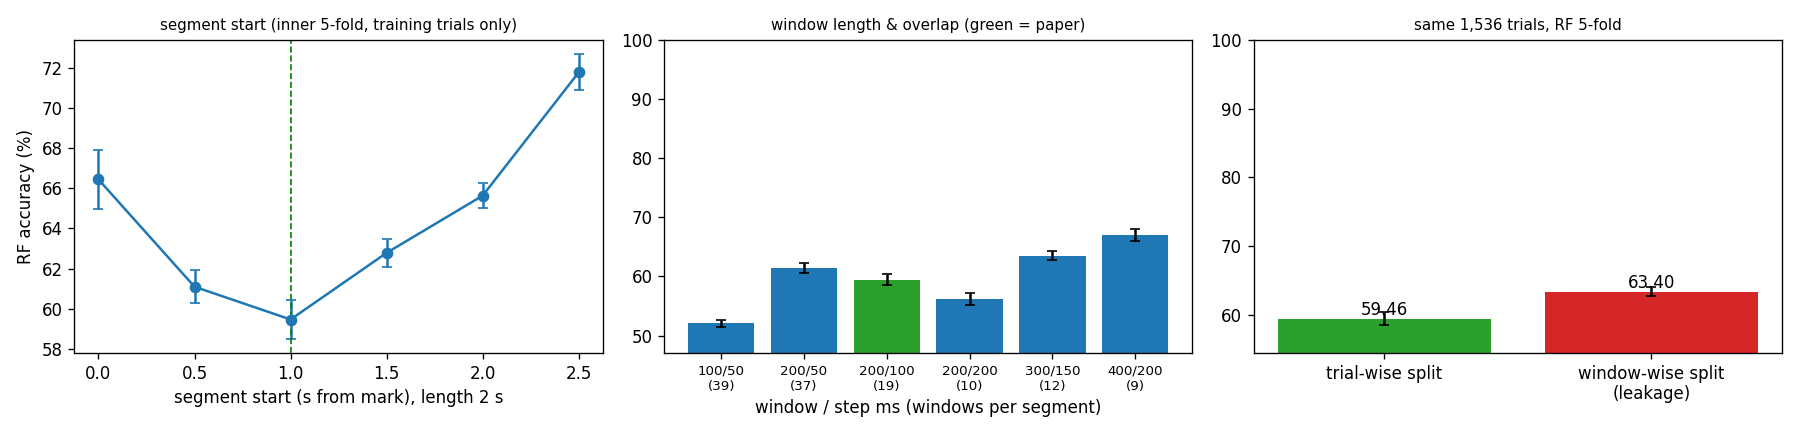

,win_ms,hop_ms,overlap,n_windows,acc,std
0,100,50,50 %,39,0.520547,0.006470
1,200,50,75 %,37,0.614770,0.008156
2,200,100,50 %,19,0.594633,0.009563
3,200,200,0 %,10,0.562168,0.010068
4,300,150,50 %,12,0.635306,0.006987
5,400,200,50 %,9,0.669549,0.010022


,split,acc,std
0,시행 단위 (올바름),0.594633,0.009563
1,윈도우 단위 (누수),0.634012,0.006032


In [9]:
display(Image('results/week2/settings_check.png'))
display(pd.read_csv('results/week2/window_length.csv'))
display(pd.read_csv('results/week2/leakage.csv'))

,unit,n_test_per_fold,acc,std
0,윈도우 1개 (200 ms),"5,837",0.594633,0.009563
1,세그먼트: 19윈도우 확률 평균,307,0.957670,0.011120
2,세그먼트: 19×25 = 475차원 연결,307,0.957031,0.012084
3,세그먼트: 윈도우 평균 25차원,307,0.895827,0.014753


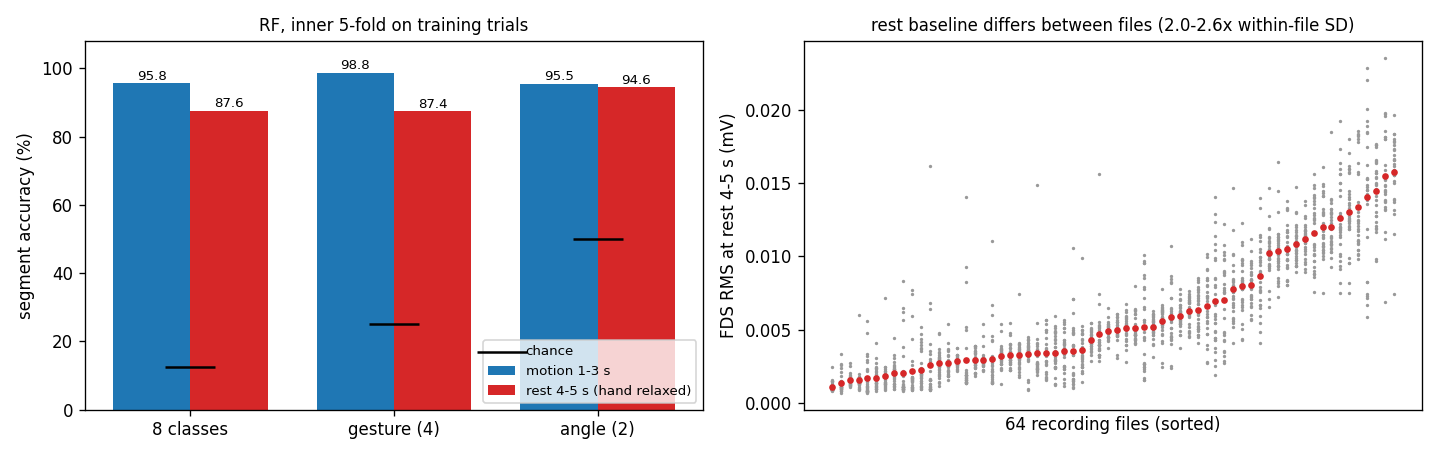

,segment,target,chance,acc,std
0,동작 1.0~3.0 s,8클래스,12.5,0.957670,0.011120
1,동작 1.0~3.0 s,손동작 4종,25.0,0.987628,0.009752
2,동작 1.0~3.0 s,각도 2종,50.0,0.955070,0.008867
3,휴식 4.0~5.0 s,8클래스,12.5,0.875646,0.013613
4,휴식 4.0~5.0 s,손동작 4종,25.0,0.874343,0.015404
5,휴식 4.0~5.0 s,각도 2종,50.0,0.945960,0.014520


In [10]:
display(pd.read_csv('results/week2/sample_unit.csv'))
display(Image('results/week2/confound.png'))
display(pd.read_csv('results/week2/rest_confound.csv'))

**정리**: 논문 수준(96 %)은 윈도우 하나가 아니라 세그먼트(19윈도우) 단위에서 나온다. 손을 쉬는 4~5 s 구간만으로도 손동작을 87 % 맞히므로, 같은 녹음 파일의 시행이 학습·평가에 섞이는 trial-wise 평가에는 녹음 세션 교란이 들어 있다. 3주차에 피험자 단위(LOSO) 평가로 이를 분리한다.